# Pricing Partial Credit Guarantees for Blended Finance: ML Default Curves and a Keras Surrogate of the Monte Carlo Pricer

When a development bank guarantees part of a country's loan, the country borrows more cheaply and for longer, and investors who could not take the full risk can come in. The hard part is the fee: what the market would charge, what the guarantee really costs the development bank, and how much subsidy lies in the gap. This notebook builds a pricer for both common guarantee structures and a fast surrogate of it.

**What it does.** It prices the **partial credit guarantees (PCGs)** that multilateral development banks (MDBs) give on loans and bonds of emerging-market sovereigns and state-owned borrowers. A Monte Carlo pricer covers two structures:

- **pari-passu** guarantees of a share of every loss;
- **first-loss** guarantees capped at a share of the outstanding amount.

The pricer has stochastic default intensity, stochastic recovery, grace periods and amortisation. It returns:

- the **market-consistent fee**;
- the **MDB cost-based fee** (expected loss with preferred-creditor recovery, plus a capital charge);
- the **spread compression** the borrower obtains, and the **subsidy** embedded in charging the MDB fee.

**Machine learning, twice.**

1. A **LightGBM** model maps World Bank fundamentals to sovereign spreads, so guarantees can be priced for countries with no market bonds (most IDA countries).
2. A **Keras 3 neural network (torch backend)** learns the Monte Carlo pricer. It prices every country and structure in milliseconds, and **SHAP** explains which terms drive the fee.

**Data.** iShares J.P. Morgan EM USD sovereign bonds (EMB) for market spreads and term structures, the U.S. Treasury curve, and World Bank WDI and WGI fundamentals with the income classification.

**Key output.** Fee grids by country, structure and tenor, the borrower's saving, the subsidy element, and a surrogate that reproduces the pricer within a few basis points at a fraction of the cost.

## 1. What a partial credit guarantee does

A PCG is an MDB promise to pay lenders a defined part of the debt service if the borrower defaults. The borrower (often a sovereign or a state-owned utility) gets two things:
- cheaper and longer funding, because part of the risk now sits with a AAA guarantor;
- access to investors who could not take the full risk.

The MDB charges an annual **guarantee fee** on the amount it guarantees.

Two structures cover most transactions:

| structure | guarantor pays at default | typical use |
|---|---|---|
| **pari-passu** | a share $\varphi$ of the lenders' loss | commercial-bank loans, policy-based guarantees |
| **first-loss** | the loss up to a cap $\kappa$ × outstanding | bond issues where a thin wrapper unlocks investment grade |

Pricing has three angles:
1. **Market-consistent fee.** It uses risk-neutral default intensities from bond spreads, so the guarantee is worth what the market would charge for it.
2. **MDB cost-based fee.** It reflects what the MDB actually expects to lose. That uses physical PDs, plus higher recoveries thanks to **preferred creditor status**, plus a charge for the capital the guarantee consumes.
3. **Blended-finance subsidy.** The difference between the two, in present value, is the subsidy element. Concessional-finance rules require it to be measured and justified.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
import shap
from scipy import optimize, stats
from scipy.interpolate import PchipInterpolator
from sklearn.model_selection import KFold, train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 11
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
ISHARES_FUNDS = {"EMB": "239572"}
WB = "https://api.worldbank.org/v2"
WDI = {
    "NY.GDP.PCAP.CD": "gdp_pc",
    "NY.GDP.MKTP.KD.ZG": "growth",
    "FP.CPI.TOTL.ZG": "inflation",
    "BN.CAB.XOKA.GD.ZS": "current_account",
    "FI.RES.TOTL.MO": "reserves_months",
    "DT.DOD.DECT.GN.ZS": "ext_debt_gni",
}
WGI = {
    "GOV_WGI_GE.EST": "gov_effectiveness",
    "GOV_WGI_RL.EST": "rule_of_law",
    "GOV_WGI_PV.EST": "political_stability",
}
# market recovery convention used to read hazards from spreads
RECOVERY_MKT = 0.40
# MDB recovery on guaranteed claims thanks to preferred creditor status
# (assumption)
RECOVERY_PCS = 0.70
# risk-neutral / physical intensity ratio for sovereigns (assumption)
RN_TO_PHYSICAL = 2.5
# capital held against the guaranteed exposure, per unit of IRB-style
# unexpected loss multiple (see §6)
CAPITAL_RATIO = 0.08
COST_OF_CAPITAL = 0.10  # hurdle on MDB equity used for the capital charge
DT_STEP = 0.5  # semi-annual payment grid
# recovery falls 10pp per unit rise in log intensity (wrong-way recovery,
# assumption)
WWR = 0.10

print(
    f"keras {keras.__version__} ({keras.backend.backend()} backend) · lightgbm"
    f" {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

keras 3.15.1 (torch backend) · lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


def fetch_holdings(ticker):
    """
    One iShares fund's holdings file (all columns as text) with its as-of date.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"], t["as_of"] = ticker, as_of
    return t


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False), errors="coerce"
)
raw = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
raw = raw[raw["Asset Class"] == "Fixed Income"]
AS_OF = pd.to_datetime(raw["as_of"].iloc[0], format="%b %d, %Y")

TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
    "{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv"
)


def fetch_par():
    t = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(y=AS_OF.year),
                headers=BROWSER_HEADERS,
                timeout=60,
            ).text
        )
    )
    t["date"] = pd.to_datetime(t["Date"], format="%m/%d/%Y")
    return t


par = cached("treasury_par", fetch_par).set_index("date").sort_index()
par = par.loc[:AS_OF].iloc[-1]
ten = {
    c: float(c.split()[0]) / (12 if "Mo" in c else 1)
    for c in par.index
    if re.match(r"^[\d.]+ (Mo|Yr)$", c)
}
pc = pd.Series({ten[c]: par[c] for c in ten}).dropna().sort_index() / 100
grid = np.arange(0.5, 30.01, 0.5)
par_g = PchipInterpolator(pc.index, pc.values)(grid)
dfs = []
# bootstrap semi-annual par bonds into discount factors
for c in par_g:
    dfs.append((1 - c / 2 * sum(dfs)) / (1 + c / 2))
zero_t = np.concatenate([[1 / 12], grid])
zero_r = np.concatenate(
    [[np.log(1 + pc.iloc[0] / 12) * 12], -np.log(np.array(dfs)) / grid]
)


def zero(t):
    return np.interp(
        np.asarray(t, float), zero_t, zero_r, left=zero_r[0], right=zero_r[-1]
    )


def DF(t):
    return np.exp(-zero(t) * np.asarray(t, float))


def schedule(maturity, coupon, settle=None):
    """
    Cash-flow times (years) and amounts per 100 face, and accrued interest, for
    a semi-annual fixed-rate bullet.
    """
    settle = AS_OF if settle is None else settle
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfd = dates[-1], sorted(dates[:-1])
    acc = coupon / 2 * (settle - prev).days / (cfd[0] - prev).days
    t = np.array([(d - settle).days / 365.25 for d in cfd])
    cf = np.full(len(t), coupon / 2)
    cf[-1] += 100
    return t, cf, acc


def zspread(maturity, coupon, clean):
    t, cf, acc = schedule(maturity, coupon)
    f = lambda s: np.sum(cf * np.exp(-(zero(t) + s) * t)) - (clean + acc)
    try:
        return optimize.brentq(f, -0.05, 0.9)
    except ValueError:
        return np.nan

## 3. Sovereign default curves from EMB bonds

Every fixed-rate sovereign bond in EMB gets a z-spread over the Treasury zero curve. A pooled regression $\log s_{cj}=a_c+b\log T_{cj}$, with one intercept per country and a common slope, gives each country a full **spread term structure** $s_c(T)=e^{a_c}T^b$. That curve fixes two things:
- the 5-year-equivalent spread used everywhere else;
- the curve's shape, for long guarantees.

Spreads become cumulative risk-neutral hazards with the credit triangle on spreads to each maturity: $H_c(T)=s_c(T)\,T/(1-R)$, with $R=40\%$. The forward intensity on each semi-annual step is the increment of $H_c$.

In [3]:
sov = raw[raw["Sector"] == "Sovereign"]
b = pd.DataFrame({
    "country": sov["Location"],
    "price": num(sov["Price"]),
    "coupon": num(sov["Coupon (%)"]),
    "maturity": pd.to_datetime(
        sov["Maturity"], format="%b %d, %Y", errors="coerce"
    ),
    "isin": sov["ISIN"],
})
b = b.dropna().drop_duplicates("isin")
b["T"] = (b["maturity"] - AS_OF).dt.days / 365.25
b = b[(b["T"] > 0.75) & (b["price"] > 15)]
b["z_bp"] = [
    zspread(m_, c_, p_) * 1e4
    for m_, c_, p_ in zip(b["maturity"], b["coupon"], b["price"])
]
b = b[b["z_bp"].between(3, 6000)].reset_index(drop=True)
b["lz"], b["lT"] = np.log(b["z_bp"]), np.log(b["T"])
dm = b.groupby("country")[["lz", "lT"]].transform(lambda x: x - x.mean())
SLOPE = float((dm["lz"] * dm["lT"]).sum() / (dm["lT"] ** 2).sum())
cty = (
    b.assign(a=b["lz"] - SLOPE * b["lT"])
    .groupby("country")
    .agg(a=("a", "median"), n_bonds=("isin", "size"), max_T=("T", "max"))
    .reset_index()
)
cty["s5"] = np.exp(cty["a"] + SLOPE * np.log(5))
cty["source"] = "market (EMB)"
print(
    f"{len(b):,} sovereign bonds of {len(cty)} countries (as of"
    f" {AS_OF:%Y-%m-%d}) · pooled term-structure slope b = {SLOPE:.3f} (a"
    f" 20-year spread is {(4 ** SLOPE):.2f}× the 5-year one)"
)
cty.sort_values("s5")[["country", "s5", "n_bonds", "max_T"]].iloc[
    np.r_[0:4, len(cty) // 2 - 2 : len(cty) // 2 + 2, -4:0]
].round(0)

494 sovereign bonds of 47 countries (as of 2026-10-19) · pooled term-structure slope b = 0.247 (a 20-year spread is 1.41× the 5-year one)


,country,s5,n_bonds,max_T
2,Azerbaijan,30.00,1,6.00
22,Kazakhstan,54.00,6,19.00
8,Chile,55.00,17,45.00
46,Uruguay,55.00,7,34.00
26,Mexico,131.00,38,84.00
16,Ghana,140.00,2,9.00
40,South Africa,147.00,13,29.00
12,Dominican Republic,153.00,18,33.00
5,Bolivia,535.00,1,5.00
45,Ukraine,582.00,8,9.00


## 4. ML default curves for countries without bonds

Most IDA countries, the main users of MDB guarantees, have no USD bonds. A **LightGBM** model is trained on the countries with EMB bonds to predict the log 5-year spread from World Bank fundamentals:
- log GDP per capita, real growth, log inflation;
- the current account, reserves in months of imports, external debt in % of GNI;
- three governance indicators.

Countries with spreads above 2,000 bp (in default or restructuring) are left out of training. The model is evaluated by 5-fold cross-validation and then applied to every low- and middle-income country with complete fundamentals. Each proxy carries an 80% band from the cross-validated residuals: with about 45 training countries, the proxies are an informed prior, not a market price. The term-structure slope from §3 extends the predicted 5-year spread to all tenors.

Gradient boosting is used here because the relation is strongly non-linear: debt matters much more when governance is weak. Monotone constraints keep the economics sensible:
- spreads fall with GDP per capita, reserves and governance;
- spreads rise with inflation and debt.

In [4]:
def wb_json(url):
    out, page = [], 1
    while True:
        j = requests.get(f"{url}&page={page}", timeout=90).json()
        out += j[1] or []
        if page >= j[0]["pages"]:
            return out
        page += 1


def fetch_macro():
    countries = pd.DataFrame([
        {
            "iso3": c["id"],
            "wb_name": c["name"],
            "region": c["region"]["value"],
            "income": c["incomeLevel"]["value"],
            "lending": c["lendingType"]["value"],
        }
        for c in wb_json(f"{WB}/country?format=json&per_page=400")
        if c["region"]["value"] != "Aggregates"
    ])
    rows = []
    for ind, name in {**WDI, **WGI}.items():
        src = 3 if ind in WGI else 2
        for o in wb_json(
            f"{WB}/country/all/indicator/{ind}?source={src}&format=json&per_page=20000&date=2019:2025"
        ):
            if o["value"] is not None:
                rows.append({
                    "wb_name": o["country"]["value"],
                    "iso3": o.get("countryiso3code") or None,
                    "var": name,
                    "year": int(o["date"]),
                    "value": o["value"],
                })
    obs = pd.DataFrame(rows)
    obs["iso3"] = obs["iso3"].fillna(
        obs["wb_name"].map(countries.set_index("wb_name")["iso3"])
    )
    latest = (
        obs.dropna(subset=["iso3"])
        .sort_values("year")
        .groupby(["iso3", "var"])["value"]
        .last()
        .unstack()
    )
    return countries.merge(latest.reset_index(), on="iso3", how="left")


macro = cached("wb_macro", fetch_macro, max_age_hours=24 * 30)
NAME_FIX = {
    "Korea (South)": "Korea, Rep.",
    "Turkey": "Turkiye",
    "Egypt": "Egypt, Arab Rep.",
    "Cote D'Ivoire (Ivory Coast)": "Cote d'Ivoire",
    "Democratic Rep of Congo": "Congo, Dem. Rep.",
    "Russia": "Russian Federation",
    "Venezuela": "Venezuela, RB",
    "Lao": "Lao PDR",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Gambia": "Gambia, The",
    "Bahamas": "Bahamas, The",
    "Slovakia": "Slovak Republic",
    "Czech Republic": "Czechia",
}
macro["log_gdp_pc"] = np.log(macro["gdp_pc"])
macro["log_infl"] = np.log1p(macro["inflation"].clip(-5, 300) / 100)
macro["ext_debt_missing"] = macro["ext_debt_gni"].isna().astype(int)
macro["ext_debt_gni"] = (
    macro["ext_debt_gni"].fillna(macro["ext_debt_gni"].median()).clip(0, 250)
)
FX = [
    "log_gdp_pc",
    "growth",
    "log_infl",
    "current_account",
    "reserves_months",
    "ext_debt_gni",
    "ext_debt_missing",
    "gov_effectiveness",
    "rule_of_law",
    "political_stability",
]
MONO = [-1, -1, 1, -1, -1, 1, 0, -1, -1, -1]
cty["wb_name"] = cty["country"].replace(NAME_FIX)
# distressed/defaulted names excluded
tr = (
    cty[cty["s5"] < 2000]
    .merge(macro, on="wb_name", how="left")
    .dropna(subset=FX)
    .reset_index(drop=True)
)
y = np.log(tr["s5"]).to_numpy()
params = dict(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=4,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    monotone_constraints=MONO,
    monotone_constraints_method="intermediate",
    verbose=-1,
    random_state=SEED,
)
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

r2 = lambda p_: 1 - np.mean((y - p_) ** 2) / np.var(y)
cv_scores = {
    "LightGBM (monotone)": [],
    "ridge on the same features": [],
    "GDP-per-capita line": [],
}
# repeated 5-fold CV: with ~45 countries one split is too noisy
for rep in range(5):
    o_g, o_r, o_l = np.zeros(len(tr)), np.zeros(len(tr)), np.zeros(len(tr))
    for a_, b_ in KFold(5, shuffle=True, random_state=rep).split(tr):
        o_g[b_] = (
            lgb.LGBMRegressor(**params)
            .fit(tr.iloc[a_][FX], y[a_])
            .predict(tr.iloc[b_][FX])
        )
        o_r[b_] = (
            make_pipeline(
                StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))
            )
            .fit(tr.iloc[a_][FX], y[a_])
            .predict(tr.iloc[b_][FX])
        )
        o_l[b_] = np.poly1d(np.polyfit(tr.iloc[a_]["log_gdp_pc"], y[a_], 1))(
            tr.iloc[b_]["log_gdp_pc"]
        )
    if rep == 0:
        oof = o_g.copy()
    for k_, o_ in zip(cv_scores, (o_g, o_r, o_l)):
        cv_scores[k_].append(r2(o_))
cv_tab = (
    pd.DataFrame(cv_scores)
    .agg(["mean", "std"])
    .T.rename(columns={"mean": "CV R² mean", "std": "CV R² s.d."})
)
resid_q = np.quantile(y - oof, [0.1, 0.9])
gbm = lgb.LGBMRegressor(**params).fit(tr[FX], y)
cand = macro[
    (
        macro["income"].isin(
            ["Low income", "Lower middle income", "Upper middle income"]
        )
    )
    & ~macro["wb_name"].isin(cty["wb_name"])
].dropna(subset=FX)
pred_l = gbm.predict(cand[FX])
prox = pd.DataFrame({
    "country": cand["wb_name"],
    "s5": np.exp(pred_l),
    "s5_low80": np.exp(pred_l + resid_q[0]),
    "s5_high80": np.exp(pred_l + resid_q[1]),
    "source": "ML proxy (LightGBM)",
    "lending": cand["lending"],
    "income": cand["income"],
})
curves = pd.concat([cty[["country", "s5", "source"]], prox], ignore_index=True)
print(
    f"{len(tr)} countries with bonds · median abs CV error"
    f" {np.median(np.abs(np.exp(oof) - tr['s5'])):.0f} bp · 80% residual band"
    f" ×{np.exp(resid_q[0]):.2f}–×{np.exp(resid_q[1]):.2f} · proxies for"
    f" {len(prox)} countries without bonds"
    f" ({(prox['lending'] == 'IDA').sum()} IDA-only,"
    f" {(prox['lending'] == 'Blend').sum()} blend)"
)
display(cv_tab.round(3))
prox.sort_values("s5", ascending=False).head(8).round(0)

43 countries with bonds · median abs CV error 52 bp · 80% residual band ×0.51–×2.03 · proxies for 71 countries without bonds (35 IDA-only, 14 blend)


,CV R² mean,CV R² s.d.
LightGBM (monotone),0.26,0.04
ridge on the same features,0.29,0.13
GDP-per-capita line,0.13,0.05


,country,s5,s5_low80,s5_high80,source,lending,income
134,Mozambique,783.00,396.00,"1,586.00",ML proxy (LightGBM),IDA,Low income
161,West Bank and Gaza,774.00,392.00,"1,569.00",ML proxy (LightGBM),Not classified,Lower middle income
13,Burundi,749.00,379.00,"1,517.00",ML proxy (LightGBM),IDA,Low income
196,Tunisia,520.00,263.00,"1,054.00",ML proxy (LightGBM),IBRD,Lower middle income
40,"Congo, Rep.",484.00,245.00,981.00,ML proxy (LightGBM),Blend,Lower middle income
123,Madagascar,481.00,243.00,974.00,ML proxy (LightGBM),IDA,Low income
137,Malawi,465.00,235.00,942.00,ML proxy (LightGBM),IDA,Low income
178,Sao Tome and Principe,456.00,231.00,923.00,ML proxy (LightGBM),IDA,Lower middle income


## 5. The Monte Carlo pricer

**Loan.** The loan has notional 100 and tenor $T$, with a grace period $g$ (interest only) followed by linear semi-annual amortisation. Outstanding principal is $N(t)$.

**Default.** The intensity is the country's forward curve times a lognormal shock, $\lambda_t=c_t\,\bar\lambda(t)\,e^{\sigma W_t-\sigma^2t/2}$. The shock adds clustering (bad countries can get worse), and a scaling constant is solved on every run, date by date, so that the **expected survival at every payment date still matches the market curve**. Without it, intensity volatility would lower default probabilities through Jensen's inequality and break the calibration.
- Default occurs in a step with probability $1-e^{-\lambda_t\Delta t}$.
- Recovery is beta-distributed (s.d. 15%) around a mean that **falls when intensity is high**: 10 pp per unit of log intensity. Recoveries are empirically lowest in default waves (Altman et al.), and this wrong-way link is what makes intensity volatility matter. With the curve calibrated date by date, the marginal default probabilities do not depend on $\sigma$; what $\sigma$ changes is *how bad* the defaults are.
- Each path's default probability per step is used directly (conditional expectation) instead of a 0/1 draw, which removes most of the simulation noise.

**Guarantee payoff at default time $\tau$.** The lenders' loss is $\ell=(1-R)\,N(\tau)$.
- **pari-passu:** the guarantor pays $\varphi\,\ell$;
- **first-loss:** the guarantor pays $\min(\ell,\ \kappa N(\tau))$.

**Fee.** The fee is paid semi-annually on the guaranteed amount ($\varphi N(t)$ or $\kappa N(t)$) while the borrower survives. The fair fee $f$ equates the present values:

$$f=\frac{E\big[D(\tau)\,\text{payout}_\tau\,1_{\tau\le T}\big]}{E\big[\sum_k \Delta t\,D(t_k)\,G(t_k)\,1_{\tau>t_k}\big]}.$$

**Outputs.**
- **Market-consistent fee:** risk-neutral intensities, market recovery 40%.
- **MDB expected loss:** the same engine with physical intensities ($\lambda^Q/2.5$) and recovery 70% on the MDB's subrogated claim (preferred creditor status).
- **Borrower's spread compression:** the fall in the fair spread of the loan to lenders once the guarantee absorbs part of the loss, measured with the same risk-neutral engine.

In [5]:
def price_pcg(
    s5,
    tenor,
    grace,
    structure,
    cover,
    sigma=0.5,
    rec_mean=RECOVERY_MKT,
    intensity_scale=1.0,
    n_paths=20_000,
    seed=SEED,
    slope=None,
):
    """
    Monte Carlo PCG pricer. Returns fair fee (bp p.a. on guaranteed amount),
    unguaranteed and guaranteed loan spreads (bp).
    """
    r_ = np.random.default_rng(seed)
    slope = SLOPE if slope is None else slope
    t = np.arange(DT_STEP, tenor + 1e-9, DT_STEP)
    # cumulative hazard
    H = (
        (s5 / 1e4)
        * (t / 5) ** slope
        * t
        / (1 - RECOVERY_MKT)
        * intensity_scale
    )
    lam = np.diff(np.r_[0, H]) / DT_STEP
    n_amort = max(len(t) - int(grace / DT_STEP), 1)
    # outstanding at start of each step
    N = (
        np.minimum(
            1.0, np.maximum(0.0, (len(t) - np.arange(len(t))) / n_amort)
        )
        * 100
    )
    W = np.cumsum(
        r_.standard_normal((n_paths, len(t))) * np.sqrt(DT_STEP), axis=1
    )
    lam_p = lam * np.exp(sigma * W - 0.5 * sigma**2 * t)
    # step-by-step calibration: mean survival matches the market curve at every
    # date
    if sigma > 0:
        surv = np.empty_like(lam_p)
        s_prev = np.ones(n_paths)
        for k_ in range(len(t)):
            target, x_, c_ = np.exp(-H[k_]), lam_p[:, k_] * DT_STEP, 1.0
            # Newton on c: mean(s_prev * exp(-c x)) = target
            for _ in range(8):
                e_ = s_prev * np.exp(-c_ * x_)
                c_ = max(
                    c_ - (e_.mean() - target) / (-(x_ * e_).mean() - 1e-15),
                    1e-4,
                )
            s_prev = s_prev * np.exp(-c_ * x_)
            surv[:, k_] = s_prev
    else:
        surv = np.exp(-np.cumsum(lam_p * DT_STEP, axis=1))
    alive_prev = np.c_[np.ones(n_paths), surv[:, :-1]]
    # probability of default inside each step, path by path
    p_def = alive_prev - surv
    # wrong-way recovery: lower when intensity is high
    m_R = np.clip(
        rec_mean - WWR * (sigma * W - 0.5 * sigma**2 * t), 0.05, 0.90
    )
    k = m_R * (1 - m_R) / 0.15**2 - 1
    R = r_.beta(m_R * k, (1 - m_R) * k)
    loss = (1 - R) * N
    gamt = cover * N
    payout = (
        cover * loss if structure == "pari-passu" else np.minimum(loss, gamt)
    )
    D = DF(t)
    pv_pay = np.mean(np.sum(p_def * payout * D, axis=1))
    pv_fee_annuity = np.mean(np.sum(surv * gamt * D * DT_STEP, axis=1))
    pv_loss = np.mean(np.sum(p_def * loss * D, axis=1))
    pv_loan_annuity = np.mean(np.sum(surv * N * D * DT_STEP, axis=1))
    return {
        "fee_bp": pv_pay / pv_fee_annuity * 1e4,
        "spread_unguaranteed_bp": pv_loss / pv_loan_annuity * 1e4,
        "spread_guaranteed_bp": (pv_loss - pv_pay) / pv_loan_annuity * 1e4,
        "pv_payout": pv_pay,
        "pv_fee_annuity": pv_fee_annuity,
    }


def mdb_fee(s5, tenor, grace, structure, cover, sigma=0.5, **kw):
    """
    Cost-based fee: physical expected loss with PCS recovery + capital charge
    on the guaranteed exposure.
    """
    el = price_pcg(
        s5,
        tenor,
        grace,
        structure,
        cover,
        sigma,
        rec_mean=RECOVERY_PCS,
        intensity_scale=1 / RN_TO_PHYSICAL,
        **kw,
    )
    pd1 = 1 - np.exp(-(s5 / 1e4) / (1 - RECOVERY_MKT) / RN_TO_PHYSICAL)
    rho = 0.12 * (1 - np.exp(-50 * pd1)) / (1 - np.exp(-50)) + 0.24 * (
        1 - (1 - np.exp(-50 * pd1)) / (1 - np.exp(-50))
    )
    k_irb = (1 - RECOVERY_PCS) * (
        stats.norm.cdf(
            (stats.norm.ppf(pd1) + np.sqrt(rho) * stats.norm.ppf(0.999))
            / np.sqrt(1 - rho)
        )
        - pd1
    )
    return (
        el["fee_bp"] + COST_OF_CAPITAL * k_irb * 1e4,
        el["fee_bp"],
        COST_OF_CAPITAL * k_irb * 1e4,
    )


demo = {
    "structure": ["pari-passu", "pari-passu", "first-loss", "first-loss"],
    "cover": [0.5, 1.0, 0.2, 0.4],
}
rows = []
for c_name in ["Colombia", "Egypt", "Kenya"]:
    s5c = float(curves.loc[curves["country"] == c_name, "s5"].iloc[0])
    for st, cv in zip(demo["structure"], demo["cover"]):
        m_ = price_pcg(s5c, 12, 3, st, cv)
        f_mdb, f_el, f_cap = mdb_fee(s5c, 12, 3, st, cv)
        rows.append({
            "country": c_name,
            "5y spread": s5c,
            "structure": f"{st} {cv:.0%}",
            "market fee (bp)": m_["fee_bp"],
            "MDB fee (bp)": f_mdb,
            "of which EL": f_el,
            "of which capital": f_cap,
            "loan spread before": m_["spread_unguaranteed_bp"],
            "loan spread after": m_["spread_guaranteed_bp"],
            "subsidy (% of notional)": (
                (m_["fee_bp"] - f_mdb) / 1e4 * m_["pv_fee_annuity"]
            ),
        })
demo_tab = pd.DataFrame(rows)
print("12-year loan, 3-year grace, intensity vol 50%:")
demo_tab.round(1)

12-year loan, 3-year grace, intensity vol 50%:


,country,5y spread,structure,market fee (bp),MDB fee (bp),of which EL,of which capital,loan spread before,loan spread after,subsidy (% of notional)
0,Colombia,180.80,pari-passu 50%,206.30,87.50,45.30,42.20,206.30,103.20,3.30
1,Colombia,180.80,pari-passu 100%,206.30,87.50,45.30,42.20,206.30,0.00,6.60
2,Colombia,180.80,first-loss 20%,327.40,161.20,119.00,42.20,206.30,140.80,1.80
3,Colombia,180.80,first-loss 40%,320.30,139.00,96.90,42.20,206.30,78.20,4.00
4,Egypt,317.20,pari-passu 50%,352.20,129.40,77.60,51.90,352.20,176.10,5.60
5,Egypt,317.20,pari-passu 100%,352.20,129.40,77.60,51.90,352.20,0.00,11.30
6,Egypt,317.20,first-loss 20%,569.40,258.70,206.80,51.90,352.20,238.30,3.20
7,Egypt,317.20,first-loss 40%,555.90,219.00,167.10,51.90,352.20,129.80,6.80
8,Kenya,369.60,pari-passu 50%,406.60,144.20,89.60,54.60,406.60,203.30,6.40
9,Kenya,369.60,pari-passu 100%,406.60,144.20,89.60,54.60,406.60,0.00,12.90


## 6. Convergence and sensitivities

Before the pricer is trusted, two checks are needed:
- the fee must converge as the number of paths grows;
- it must react sensibly to its inputs.

The capital charge in the MDB fee is the Basel IRB unexpected loss at 99.9% on the guaranteed exposure, with LGD $1-R_\text{PCS}$, times a 10% cost of capital. It is a simple, transparent stand-in for an MDB's own capital-adequacy model.

In [6]:
s5_col = float(curves.loc[curves["country"] == "Colombia", "s5"].iloc[0])
conv = pd.DataFrame([
    {
        "paths": n,
        **{
            f"seed {s_}": price_pcg(
                s5_col, 12, 3, "first-loss", 0.3, n_paths=n, seed=s_
            )["fee_bp"]
            for s_ in range(3)
        },
    }
    for n in [1000, 4000, 16000, 64000]
]).set_index("paths")
conv["spread across seeds (bp)"] = conv.max(axis=1) - conv.min(axis=1)
sens = {}
for name, grid, kw in [
    ("tenor (years)", [5, 8, 12, 16, 20], "tenor"),
    ("intensity vol σ", [0.0, 0.25, 0.5, 0.75, 1.0], "sigma"),
    ("first-loss cap κ", [0.1, 0.2, 0.3, 0.4, 0.6], "cover"),
]:
    base = dict(
        s5=s5_col,
        tenor=12,
        grace=3,
        structure="first-loss",
        cover=0.3,
        sigma=0.5,
        n_paths=16000,
    )
    sens[name] = pd.Series(
        {g: price_pcg(**{**base, kw: g})["fee_bp"] for g in grid}
    )
display(conv.round(2))
pd.concat(sens, axis=1).round(1)

,seed 0,seed 1,seed 2,spread across seeds (bp)
paths,,,,
1000,325.43,325.37,325.50,0.13
4000,325.36,325.34,325.44,0.09
16000,325.38,325.33,325.36,0.05
64000,325.38,325.37,325.40,0.03


,tenor (years),intensity vol σ,first-loss cap κ
5.00,285.00,NaN,NaN
8.00,305.50,NaN,NaN
12.00,325.40,NaN,NaN
16.00,339.20,NaN,NaN
20.00,349.10,NaN,NaN
0.00,NaN,326.50,NaN
0.25,NaN,326.20,NaN
0.50,NaN,325.40,NaN
0.75,NaN,323.30,NaN
1.00,NaN,318.20,NaN


## 7. Keras surrogate of the pricer, explained with SHAP

A full Monte Carlo run takes a fraction of a second. An MDB pricing desk, or a structuring tool that searches over thousands of term sheets, needs something faster and smooth in its inputs.

**Training set.** 16,000 random term sheets are priced with 4,000 paths each. The inputs:
- 5-year spread, 40–1,500 bp, sampled log-uniformly;
- term-structure slope, tenor 5–20 years, grace 0–5 years;
- structure;
- coverage: $\varphi$ 0.2–1 or $\kappa$ 0.05–0.6;
- intensity volatility 0–1;
- mean recovery 20–60%.

The target is the log of the fee relative to the 5-year spread, so the network learns how the structure transforms credit risk rather than the credit level itself.

**Network.** The network is a **Keras 3** multilayer perceptron on the torch backend: inputs standardised, 3×128 SiLU layers, Adam, early stopping. It is checked on a hold-out set against a **fresh Monte Carlo at 64,000 paths**, so the surrogate is compared with the truth rather than with noisy labels.

**SHAP.** A permutation explainer on the surrogate attributes each fee to its inputs. This is the explainability a credit committee asks for: "why is this guarantee 180 bp?"

In [7]:
N_TRAIN = 16_000
U = rng.random((N_TRAIN, 8))
X = pd.DataFrame({
    "log_s5": np.log(40) + U[:, 0] * (np.log(1500) - np.log(40)),
    "slope": SLOPE + (U[:, 1] - 0.5) * 0.4,
    "tenor": 5 + U[:, 2] * 15,
    "grace": U[:, 3] * 5,
    "first_loss": (U[:, 4] < 0.5).astype(float),
    "cover_u": U[:, 5],
    "sigma": U[:, 6],
    "recovery": 0.2 + U[:, 7] * 0.4,
})
X["grace"] = np.minimum(X["grace"], X["tenor"] - 1.5)
X["cover"] = np.where(
    X["first_loss"] == 1, 0.05 + X["cover_u"] * 0.55, 0.2 + X["cover_u"] * 0.8
)
X = X.drop(columns="cover_u")
t0 = time.perf_counter()
yfee = np.array([
    price_pcg(
        np.exp(r.log_s5),
        r.tenor,
        r.grace,
        "first-loss" if r.first_loss else "pari-passu",
        r.cover,
        r.sigma,
        r.recovery,
        n_paths=4000,
        seed=int(i),
        slope=r.slope,
    )["fee_bp"]
    for i, r in enumerate(X.itertuples())
])
mc_time = (time.perf_counter() - t0) / N_TRAIN
FEAT = list(X.columns)
mu, sd = X.mean(), X.std()
Xs = ((X - mu) / sd).to_numpy("float32")
# learn the fee relative to the spread
Y = (np.log(yfee) - X["log_s5"].to_numpy()).astype("float32")[:, None]
Xtr, Xte, Ytr, Yte, itr, ite = train_test_split(
    Xs, Y, np.arange(N_TRAIN), test_size=0.15, random_state=SEED
)
net = keras.Sequential([
    keras.Input((len(FEAT),)),
    keras.layers.Dense(128, activation="silu"),
    keras.layers.Dense(128, activation="silu"),
    keras.layers.Dense(128, activation="silu"),
    keras.layers.Dense(1),
])
net.compile(optimizer=keras.optimizers.Adam(2e-3), loss="mse")
hist = net.fit(
    Xtr,
    Ytr,
    validation_split=0.15,
    epochs=300,
    batch_size=256,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=25, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=10),
    ],
)
surrogate = lambda Xdf: np.exp(
    net.predict(
        ((Xdf[FEAT] - mu) / sd).to_numpy("float32"), verbose=0, batch_size=4096
    )[:, 0]
    + Xdf["log_s5"].to_numpy()
)
# Truth check on 300 hold-out sheets at 64k paths
chk = X.iloc[ite[:300]]
truth = np.array([
    price_pcg(
        np.exp(r.log_s5),
        r.tenor,
        r.grace,
        "first-loss" if r.first_loss else "pari-passu",
        r.cover,
        r.sigma,
        r.recovery,
        n_paths=64_000,
        seed=10_000 + i,
        slope=r.slope,
    )["fee_bp"]
    for i, r in enumerate(chk.itertuples())
])
pred = surrogate(chk)
t0 = time.perf_counter()
_ = surrogate(pd.concat([X] * 10))
nn_time = (time.perf_counter() - t0) / (10 * N_TRAIN)
err = pd.DataFrame({
    "truth (64k paths)": truth,
    "surrogate": pred,
    "MC label (4k paths)": yfee[ite[:300]],
})
summary = pd.Series({
    "surrogate MAE vs truth (bp)": np.mean(np.abs(pred - truth)),
    "surrogate median rel. error": np.median(np.abs(pred / truth - 1)),
    "4k-path MC MAE vs truth (bp)": np.mean(np.abs(yfee[ite[:300]] - truth)),
    "MC ms per sheet (4k paths)": mc_time * 1e3,
    "surrogate µs per sheet": nn_time * 1e6,
    "speed-up ×": mc_time / nn_time,
    "epochs": len(hist.history["loss"]),
})
summary.round(3).to_frame("value")

,value
surrogate MAE vs truth (bp),2.52
surrogate median rel. error,0.00
4k-path MC MAE vs truth (bp),0.66
MC ms per sheet (4k paths),21.44
surrogate µs per sheet,2.19
speed-up ×,"9,800.13"
epochs,200.00


In [8]:
bg = X.sample(100, random_state=SEED)
expl = shap.PermutationExplainer(
    lambda a: np.log(surrogate(pd.DataFrame(a, columns=FEAT))), bg
)
sv = expl(X.iloc[ite[:400]], silent=True)
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=FEAT).sort_values(
    ascending=False
)
shap_imp.round(3).to_frame("mean |SHAP| on log fee")

,mean |SHAP| on log fee
log_s5,0.92
first_loss,0.20
recovery,0.10
tenor,0.04
cover,0.04
slope,0.01
grace,0.01
sigma,0.01


## 8. Fee grids for every country: market vs MDB, and the subsidy

The surrogate prices a 12-year loan with 3-year grace for all countries (market spreads and ML proxies) under four structures: pari-passu 50% and 100%, first-loss 20% and 40%. Two lighter checks run alongside:
- the MDB fee is computed with the Monte Carlo engine, at a lower path count, for the 5 largest economies in each source group;
- the surrogate is validated once more against the engine on these real cases.

In [9]:
STRUCTS = [
    ("pari-passu", 0.5),
    ("pari-passu", 1.0),
    ("first-loss", 0.2),
    ("first-loss", 0.4),
]
grid = pd.concat(
    [
        pd.DataFrame({
            "country": curves["country"],
            "source": curves["source"],
            "log_s5": np.log(curves["s5"]),
            "slope": SLOPE,
            "tenor": 12.0,
            "grace": 3.0,
            "first_loss": float(st == "first-loss"),
            "sigma": 0.5,
            "recovery": RECOVERY_MKT,
            "cover": cv,
            "structure": f"{st} {cv:.0%}",
        })
        for st, cv in STRUCTS
    ],
    ignore_index=True,
)
grid["market_fee_bp"] = surrogate(grid)
fees = grid.pivot_table(
    index=["country", "source"], columns="structure", values="market_fee_bp"
).reset_index()
fees["s5"] = curves.set_index("country").loc[fees["country"], "s5"].to_numpy()
mdb_rows = []
for c_name in [
    "Colombia",
    "Brazil",
    "Mexico",
    "Egypt",
    "Nigeria",
    "Kenya",
    "Pakistan",
    "Ghana",
] + list(prox.sort_values("s5")["country"].iloc[[5, 20, 40, -10]]):
    if c_name not in set(curves["country"]):
        continue
    s5c = float(curves.loc[curves["country"] == c_name, "s5"].iloc[0])
    for st, cv in STRUCTS[:1] + STRUCTS[2:3]:
        m_ = price_pcg(s5c, 12, 3, st, cv, n_paths=16000)
        f_mdb, f_el, f_cap = mdb_fee(s5c, 12, 3, st, cv, n_paths=16000)
        sur = float(
            surrogate(
                pd.DataFrame([{
                    "log_s5": np.log(s5c),
                    "slope": SLOPE,
                    "tenor": 12.0,
                    "grace": 3.0,
                    "first_loss": float(st == "first-loss"),
                    "sigma": 0.5,
                    "recovery": RECOVERY_MKT,
                    "cover": cv,
                }])
            )[0]
        )
        mdb_rows.append({
            "country": c_name,
            "source": curves.loc[curves["country"] == c_name, "source"].iloc[
                0
            ],
            "s5": s5c,
            "structure": f"{st} {cv:.0%}",
            "market fee MC": m_["fee_bp"],
            "market fee surrogate": sur,
            "MDB fee": f_mdb,
            "MDB EL part": f_el,
            "MDB capital part": f_cap,
            "spread before": m_["spread_unguaranteed_bp"],
            "spread after": m_["spread_guaranteed_bp"],
            "subsidy % notional": (
                (m_["fee_bp"] - f_mdb) / 1e4 * m_["pv_fee_annuity"]
            ),
        })
mdb_tab = pd.DataFrame(mdb_rows)
display(fees.sort_values("s5").iloc[:: max(1, len(fees) // 12)].round(0))
mdb_tab.round(1)

structure,country,source,first-loss 20%,first-loss 40%,pari-passu 100%,pari-passu 50%,s5
23,China,ML proxy (LightGBM),37.00,37.00,25.00,25.00,21.00
22,Chile,market (EMB),99.00,97.00,64.00,64.00,55.00
114,Viet Nam,ML proxy (LightGBM),132.00,130.00,85.00,85.00,73.00
30,Dominica,ML proxy (LightGBM),155.00,153.00,100.00,100.00,86.00
27,Costa Rica,market (EMB),193.00,189.00,123.00,123.00,106.00
68,Mexico,market (EMB),238.00,233.00,151.00,151.00,131.00
70,Mongolia,ML proxy (LightGBM),280.00,274.00,177.00,177.00,155.00
25,Comoros,ML proxy (LightGBM),307.00,301.00,193.00,194.00,170.00
61,Libya,ML proxy (LightGBM),363.00,355.00,227.00,227.00,201.00
34,El Salvador,market (EMB),443.00,433.00,275.00,276.00,246.00


,country,source,s5,structure,market fee MC,market fee surrogate,MDB fee,MDB EL part,MDB capital part,spread before,spread after,subsidy % notional
0,Colombia,market (EMB),180.80,pari-passu 50%,206.20,205.40,87.60,45.50,42.20,206.20,103.10,3.30
1,Colombia,market (EMB),180.80,first-loss 20%,327.40,326.40,161.30,119.10,42.20,206.20,140.70,1.80
2,Brazil,market (EMB),126.10,pari-passu 50%,145.80,145.30,68.20,32.10,36.10,145.80,72.90,2.20
3,Brazil,market (EMB),126.10,first-loss 20%,229.20,228.50,119.50,83.40,36.10,145.80,99.90,1.30
4,Mexico,market (EMB),131.40,pari-passu 50%,151.60,151.20,70.20,33.40,36.80,151.60,75.80,2.30
5,Mexico,market (EMB),131.40,first-loss 20%,238.60,238.00,123.60,86.90,36.80,151.60,103.90,1.30
6,Egypt,market (EMB),317.20,pari-passu 50%,352.00,350.20,129.60,77.70,51.90,352.00,176.00,5.60
7,Egypt,market (EMB),317.20,first-loss 20%,569.40,567.20,258.80,206.90,51.90,352.00,238.10,3.10
8,Nigeria,market (EMB),221.20,pari-passu 50%,250.00,248.90,100.80,55.20,45.60,250.00,125.00,4.00
9,Nigeria,market (EMB),221.20,first-loss 20%,399.40,398.20,190.90,145.30,45.60,250.00,170.20,2.20


## 9. Charts

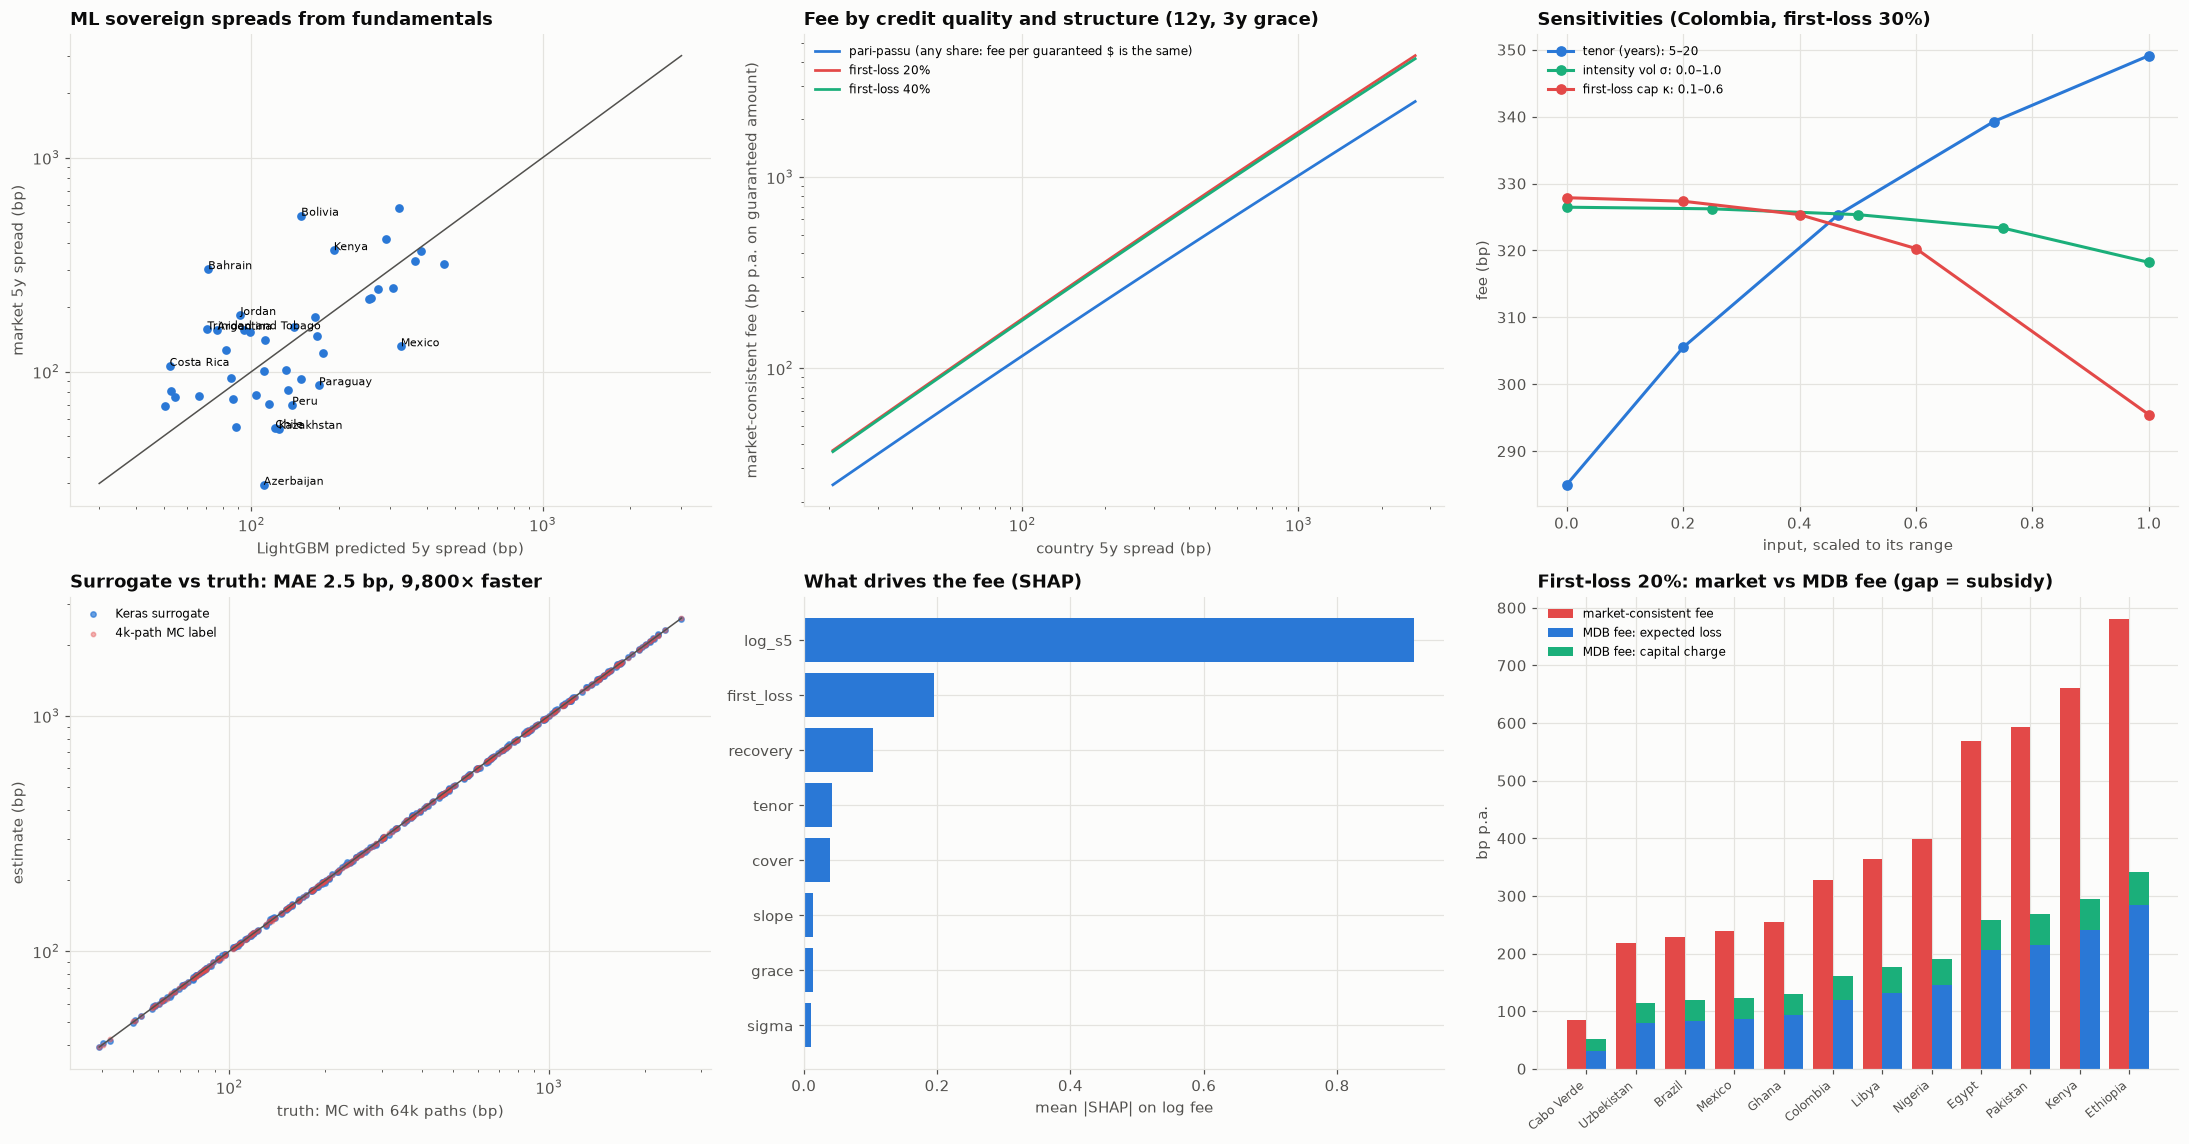

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
ax.scatter(
    np.exp(oof),
    tr["s5"],
    s=22,
    color=PALETTE[0],
    label="countries with bonds (CV prediction)",
)
for _, r in tr.iterrows():
    if abs(np.log(r["s5"]) - oof[_]) > 0.6:
        ax.annotate(r["country"], (np.exp(oof[_]), r["s5"]), fontsize=7)
ax.plot([30, 3000], [30, 3000], color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("LightGBM predicted 5y spread (bp)")
ax.set_ylabel("market 5y spread (bp)")
ax.set_title("ML sovereign spreads from fundamentals")
ax = axes[0, 1]
for col, c, lab in zip(
    ["pari-passu 50%", "first-loss 20%", "first-loss 40%"],
    [PALETTE[0], PALETTE[7], PALETTE[2]],
    [
        "pari-passu (any share: fee per guaranteed $ is the same)",
        "first-loss 20%",
        "first-loss 40%",
    ],
):
    f_ = fees.sort_values("s5")
    ax.plot(f_["s5"], f_[col], color=c, lw=1.8, label=lab)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("country 5y spread (bp)")
ax.set_ylabel("market-consistent fee (bp p.a. on guaranteed amount)")
ax.set_title("Fee by credit quality and structure (12y, 3y grace)")
ax.legend(fontsize=8)
ax = axes[0, 2]
for name, c in zip(sens, [PALETTE[0], PALETTE[2], PALETTE[7]]):
    s_ = sens[name]
    ax.plot(
        (s_.index - s_.index.min()) / (s_.index.max() - s_.index.min()),
        s_.values,
        marker="o",
        color=c,
        label=f"{name}: {s_.index.min()}–{s_.index.max()}",
    )
ax.set_xlabel("input, scaled to its range")
ax.set_ylabel("fee (bp)")
ax.set_title("Sensitivities (Colombia, first-loss 30%)")
ax.legend(fontsize=8)
ax = axes[1, 0]
ax.scatter(
    truth, pred, s=12, color=PALETTE[0], alpha=0.7, label="Keras surrogate"
)
ax.scatter(
    truth,
    yfee[ite[:300]],
    s=8,
    color=PALETTE[7],
    alpha=0.4,
    label="4k-path MC label",
)
ax.plot(
    [truth.min(), truth.max()], [truth.min(), truth.max()], color=INK_2, lw=1
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("truth: MC with 64k paths (bp)")
ax.set_ylabel("estimate (bp)")
ax.set_title(
    f"Surrogate vs truth: MAE {summary.iloc[0]:.1f} bp,"
    f" {summary['speed-up ×']:,.0f}× faster"
)
ax.legend(fontsize=8)
ax = axes[1, 1]
ax.barh(shap_imp.index[::-1], shap_imp.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| on log fee")
ax.set_title("What drives the fee (SHAP)")
ax = axes[1, 2]
mt = mdb_tab[mdb_tab["structure"] == "first-loss 20%"].sort_values("s5")
xx = np.arange(len(mt))
ax.bar(
    xx - 0.2,
    mt["market fee MC"],
    0.4,
    color=PALETTE[7],
    label="market-consistent fee",
)
ax.bar(
    xx + 0.2,
    mt["MDB EL part"],
    0.4,
    color=PALETTE[0],
    label="MDB fee: expected loss",
)
ax.bar(
    xx + 0.2,
    mt["MDB capital part"],
    0.4,
    bottom=mt["MDB EL part"],
    color=PALETTE[2],
    label="MDB fee: capital charge",
)
ax.set_xticks(xx)
ax.set_xticklabels(mt["country"], rotation=40, fontsize=8, ha="right")
ax.set_ylabel("bp p.a.")
ax.set_title("First-loss 20%: market vs MDB fee (gap = subsidy)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_pcg_pricing_surrogate")
plt.show()

## 10. Reading the results and limitations

**Default curves.**
- EMB gives market curves for 47 sovereigns. The pooled term-structure slope (0.25) makes a 20-year spread about 1.4 times the 5-year one, which is why long guarantees cost more per year (§6: 285 bp at 5 years, 349 bp at 20 years for Colombia, first-loss 30%).
- **The ML spread model is honest about its limits.** On 43 non-distressed countries, LightGBM with monotone constraints reaches a cross-validated R² of about 0.26 ± 0.04. A ridge on the same features gets 0.29 ± 0.13 (better on average, much less stable), and GDP per capita alone 0.13.
- Fundamentals explain only part of sovereign spreads; market access, IMF programmes and recent restructurings matter too. The proxies for 71 countries without bonds (35 IDA-only) therefore carry an **80% band of roughly ×0.5 to ×2**. That is the right way to present them to a credit committee: an informed prior to combine with the MDB's own country rating, not a price.

**Pricing.**
- **Pari-passu guarantees cost the loan spread per guaranteed dollar.** For Colombia that is about 206 bp a year on a 12-year loan with 3-year grace; for Kenya about 406 bp. The guarantee simply moves a slice of the risk. The borrower's spread on the whole loan halves with a 50% guarantee.

**First-loss guarantees are more expensive per guaranteed dollar but more efficient per dollar of spread saved.** A 20% first-loss wrapper for Colombia costs about 327 bp on the guaranteed amount but cuts the loan spread from 206 to 141 bp. Because the cap (20%) is below the loss given default (60%), the guarantor pays out in almost every default, so the fee approaches the default intensity.

As the cap rises past the LGD, the fee per guaranteed dollar falls: 295 bp at κ = 60%.

- **Intensity volatility matters only through wrong-way recovery.** With the curve calibrated date by date, marginal default probabilities do not change with σ. What changes is that defaults happen when intensity is high and recoveries are low. That raises pari-passu fees and barely moves capped first-loss fees, which are insensitive to recovery by design.

**The subsidy element.** The MDB's cost-based fee is about **40–45% of the market fee**: for Colombia, 88 bp against 206 bp (pari-passu) and 161 bp against 327 bp (first-loss 20%). It reflects:
- physical rather than risk-neutral PDs;
- a 70% preferred-creditor recovery;
- a 10% cost of capital.

Charging the MDB fee transfers a present value of about **3.3% of the loan notional** to a Colombian borrower with a 50% pari-passu guarantee, and 6–7% to Kenya or Ethiopia. That is the number concessional-finance rules require an MDB to measure and justify.

**Surrogate.**
- The Keras network (3×128, SiLU, torch backend) reproduces the Monte Carlo pricer with a **mean absolute error of 2.5 bp** against a 64,000-path truth, a median relative error of 0.4%, at about **10,000 times** the speed (2 µs vs 21 ms per term sheet).
- Its error is larger than that of a 4,000-path run (0.7 bp), so for a single deal the engine remains the reference. For grids, structuring searches or a live pricing tool, the surrogate is accurate enough.
- **SHAP** confirms the economics. The country spread dominates (mean |SHAP| 0.92 on the log fee), followed by the structure (pari-passu vs first-loss, 0.20) and recovery (0.10); tenor and coverage are second order.

**Limitations.**
- The physical/risk-neutral ratio (2.5), the preferred-creditor recovery (70%) and the capital rule are assumptions; the MDB fee scales directly with them.
- The guarantor is assumed default-free, and the borrower's and guarantor's credit are not correlated.
- Portfolio effects across guarantees (country concentration) are not priced here; they belong in the capital charge.
- Recovery is the same for lenders and guarantor, while in practice subrogation and cash-flow waterfalls differ by deal.

In [11]:
cty.to_csv(OUT_DIR / "sovereign_curves_market.csv", index=False)
prox.to_csv(OUT_DIR / "sovereign_spread_ml_proxies.csv", index=False)
cv_tab.to_csv(OUT_DIR / "spread_model_cv.csv")
demo_tab.to_csv(OUT_DIR / "pricing_examples.csv", index=False)
conv.to_csv(OUT_DIR / "mc_convergence.csv")
pd.concat(sens, axis=1).to_csv(OUT_DIR / "sensitivities.csv")
summary.to_csv(OUT_DIR / "surrogate_accuracy_speed.csv", header=["value"])
shap_imp.to_csv(
    OUT_DIR / "surrogate_shap_importance.csv", header=["mean_abs_shap"]
)
fees.to_csv(OUT_DIR / "fee_grid_all_countries.csv", index=False)
mdb_tab.to_csv(OUT_DIR / "market_vs_mdb_fee_subsidy.csv", index=False)
net.save(OUT_DIR / "pcg_fee_surrogate.keras")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_pcg_pricing_surrogate.png, fee_grid_all_countries.csv, market_vs_mdb_fee_subsidy.csv, mc_convergence.csv, pcg_fee_surrogate.keras, pricing_examples.csv, sensitivities.csv, sovereign_curves_market.csv, sovereign_spread_ml_proxies.csv, spread_model_cv.csv, surrogate_accuracy_speed.csv, surrogate_shap_importance.csv


## References

### Finance and regulation

- Humphrey, C. (2017). He who pays the piper calls the tune: Credit rating agencies and multilateral development banks. *The Review of International Organizations, 12*(2), 281–306. https://doi.org/10.1007/s11558-017-9271-6
- Duffie, D., & Singleton, K. J. (1999). Modeling term structures of defaultable bonds. *The Review of Financial Studies, 12*(4), 687–720. https://doi.org/10.1093/rfs/12.4.687
- Longstaff, F. A., Pan, J., Pedersen, L. H., & Singleton, K. J. (2011). How sovereign is sovereign credit risk? *American Economic Journal: Macroeconomics, 3*(2), 75–103. https://doi.org/10.1257/mac.3.2.75
- Merton, R. C. (1977). An analytic derivation of the cost of deposit insurance and loan guarantees: An application of modern option pricing theory. *Journal of Banking & Finance, 1*(1), 3–11. https://doi.org/10.1016/0378-4266(77)90015-2

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Ferguson, R., & Green, A. (2018). Deeply learning derivatives. *arXiv*. https://arxiv.org/abs/1809.02233
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1